# FraudGuard: Credit Card Fraud Detection

## 1. Project Overview

Credit card fraud detection is a binary classification problem where the goal is to identify whether a transaction is legitimate or fraudulent.

In this project, we will work with a real-world credit card transaction dataset containing 284,807 transactions, of which only 492 are fraudulent. This means fraudulent transactions represent only a very small portion of the complete dataset.

This makes the problem challenging because a model could achieve very high accuracy simply by predicting every transaction as legitimate. However, such a model would fail at the actual goal of detecting fraud.

Therefore, this project focuses on handling highly imbalanced data and evaluating the model using metrics that are more meaningful for fraud detection, such as precision, recall, F1-score, ROC-AUC, and Precision-Recall AUC.

### Objectives

- Understand and explore the transaction data
- Analyze the severe class imbalance
- Scale the `Amount` and `Time` features
- Split the data using stratification
- Build a baseline Logistic Regression model
- Handle class imbalance using class weights and SMOTE
- Train a Random Forest classifier
- Compare models using appropriate evaluation metrics
- Tune the classification decision threshold
- Select and evaluate the final model

### Dataset

The dataset used in this project is the **Credit Card Fraud Detection** dataset from Kaggle.

It contains anonymized transaction features along with a `Class` target variable:

- `Class = 0` → Legitimate transaction
- `Class = 1` → Fraudulent transaction

The dataset contains:

- **284,807 total transactions**
- **492 fraudulent transactions**
- Approximately **0.17% fraudulent transactions**

### Why This Project Matters

Fraud detection is a highly imbalanced classification problem. Since fraudulent transactions are extremely rare compared with legitimate transactions, accuracy alone can give a misleading picture of model performance.

For example, a model that predicts every transaction as legitimate could achieve around 99.8% accuracy while detecting zero fraudulent transactions.

Therefore, this project will focus on **precision, recall, F1-score, ROC-AUC, and Precision-Recall AUC** to properly evaluate how well the model detects fraud.

### Key Learning Outcomes

By completing this project, we will learn:

- How to work with highly imbalanced datasets
- Why accuracy can be misleading
- How stratified train-test splitting preserves class proportions
- How feature scaling works
- How class weights can help handle imbalance
- How SMOTE creates synthetic minority-class samples
- How Logistic Regression and Random Forest can be used for fraud detection
- How to evaluate classification models using appropriate metrics
- How decision threshold tuning affects precision and recall

The final goal is not simply to achieve a high accuracy score, but to develop a model that can meaningfully identify fraudulent transactions and justify its performance using appropriate evaluation metrics.


## 2. Import Required Libraries

In [1]:
# Import libraries for data manipulation
import pandas as pd
import numpy as np

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import libraries for data preprocessing and model building
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Import machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    auc
)

# Import SMOTE for handling class imbalance
from imblearn.over_sampling import SMOTE

# Set display options for easier dataset inspection
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Set a consistent style for visualizations
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Load the Dataset

In [4]:
# Load the credit card fraud dataset
df = pd.read_csv(r"C:\Users\humai\Intern\FraudGuard\Data\creditcard.csv")


## 4. Understand the Dataset

In [5]:
# Display the number of rows and columns
print("Dataset Shape:")
print(df.shape)

Dataset Shape:
(284807, 31)


In [6]:
# Display the column names
print("\nColumn Names:")
print(df.columns.tolist())



Column Names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [7]:
# Display basic information about the dataset
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21 

In [8]:

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


In [18]:
# Check for missing values
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [9]:
# Check for duplicate rows
print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())


Number of Duplicate Rows:
1081


In [10]:
# Display statistical summary of numerical columns
print("\nStatistical Summary:")
display(df.describe())


Statistical Summary:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,2.238554e-15,1.724421e-15,-1.245415e-15,8.238900e-16,1.213481e-15,4.866699e-15,1.436219e-15,-3.768179e-16,9.707851e-16,1.036249e-15,6.418678e-16,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,1.088850e+00,1.020713e+00,9.992014e-01,9.952742e-01,9.585956e-01,9.153160e-01,8.762529e-01,8.493371e-01,8.381762e-01,8.140405e-01,7.709250e-01,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,-2.458826e+01,-4.797473e+00,-1.868371e+01,-5.791881e+00,-1.921433e+01,-4.498945e+00,-1.412985e+01,-2.516280e+01,-9.498746e+00,-7.213527e+00,-5.449772e+01,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,-5.354257e-01,-7.624942e-01,-4.055715e-01,-6.485393e-01,-4.255740e-01,-5.828843e-01,-4.680368e-01,-4.837483e-01,-4.988498e-01,-4.562989e-01,-2.117214e-01,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,-9.291738e-02,-3.275735e-02,1.400326e-01,-1.356806e-02,5.060132e-02,4.807155e-02,6.641332e-02,-6.567575e-02,-3.636312e-03,3.734823e-03,-6.248109e-02,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,4.539234e-01,7.395934e-01,6.182380e-01,6.625050e-01,4.931498e-01,6.488208e-01,5.232963e-01,3.996750e-01,5.008067e-01,4.589494e-01,1.330408e-01,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,2.374514e+01,1.201891e+01,7.848392e+00,7.126883e+00,1.052677e+01,8.877742e+00,1.731511e+01,9.253526e+00,5.041069e+00,5.591971e+00,3.942090e+01,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


### Observation

The dataset contains 284,807 transactions and 31 columns. All columns contain 284,807 non-null values, indicating that there are no missing values in the dataset.

The dataset consists mainly of numerical features, with `Class` stored as an integer representing the target variable. The `Time` and `Amount` features are also numerical, while `V1` to `V28` represent anonymized transaction features.

A total of 1,081 duplicate rows were identified. These duplicates will be considered carefully during the preprocessing stage rather than being removed without further investigation.

The statistical summary shows that the numerical features have different distributions and scales. Feature scaling will therefore be important when preparing the data for models such as Logistic Regression.

## 5. Exploratory Data Analysis (EDA)

In [30]:
# Inspect the Target Variable

print("Transaction Class Counts:")
print(df["Class"].value_counts())

Transaction Class Counts:
Class
0    284315
1       492
Name: count, dtype: int64


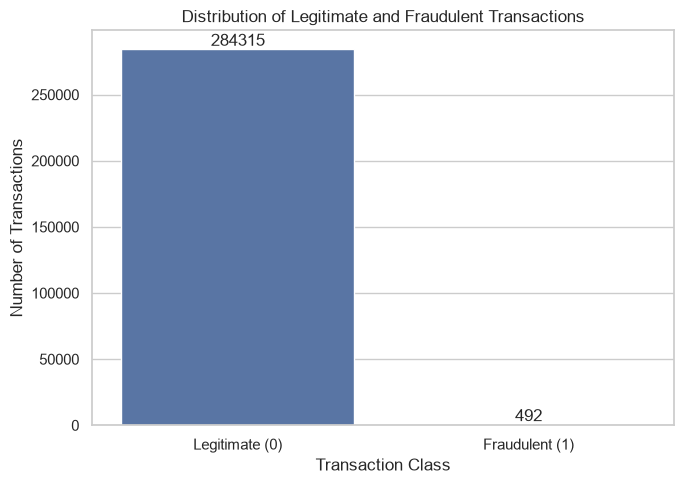

In [20]:
# Visualize Class Distribution

plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x="Class")

plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate (0)", "Fraudulent (1)"])

# Add transaction counts above the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%d")

plt.tight_layout()
plt.show()

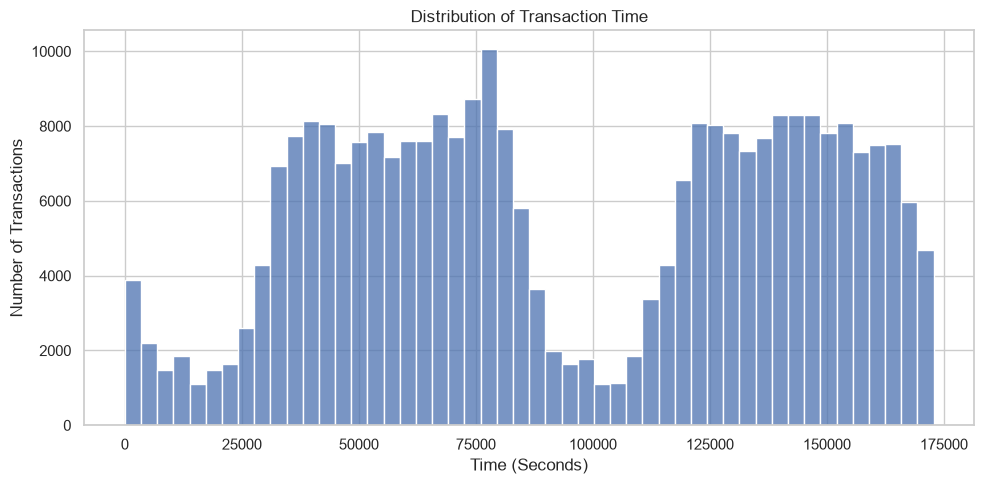

In [21]:
# Analyze Transaction Time

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Time", bins=50)

plt.title("Distribution of Transaction Time")
plt.xlabel("Time (Seconds)")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

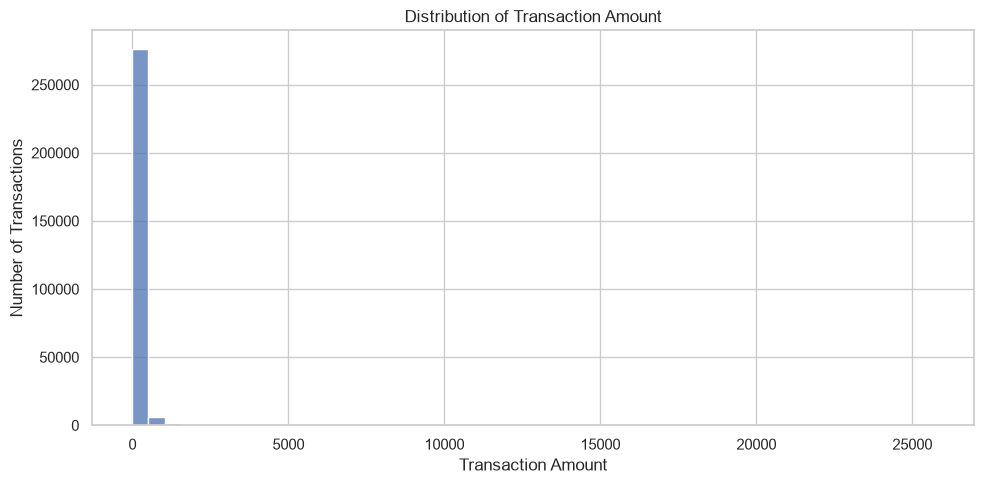

In [22]:
# Analyze Transaction Amount

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Amount", bins=50)

plt.title("Distribution of Transaction Amount")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

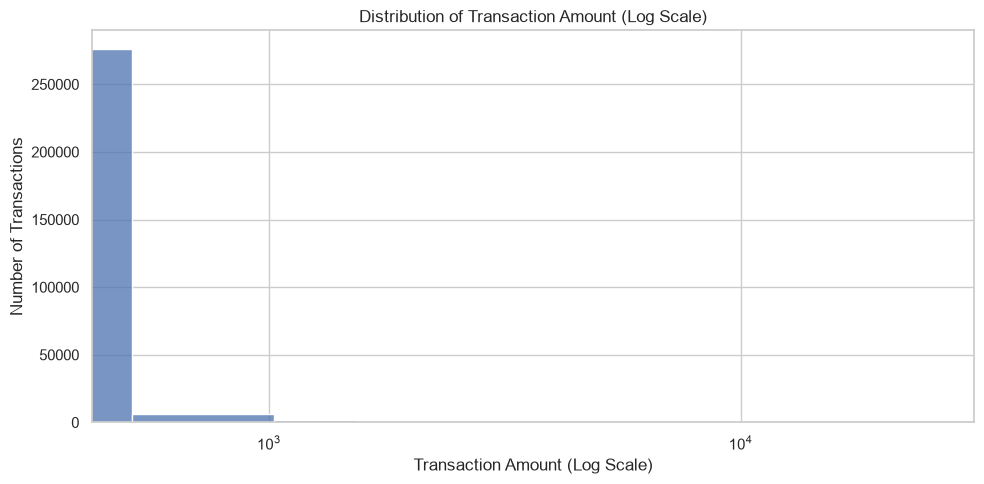

In [23]:
# Transaction Amount Distribution on a Log Scale

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Amount", bins=50)

plt.xscale("log")

plt.title("Distribution of Transaction Amount (Log Scale)")
plt.xlabel("Transaction Amount (Log Scale)")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

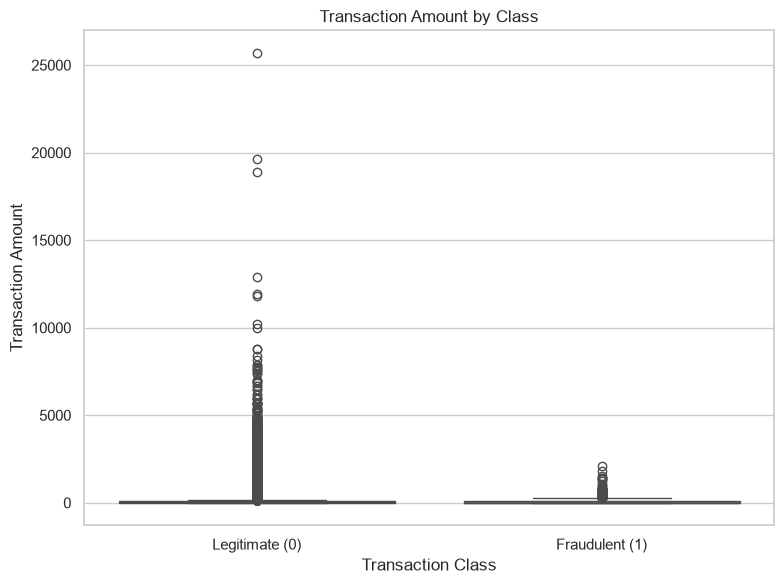

In [24]:
# Transaction Amount by Class
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)

plt.title("Transaction Amount by Class")
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount")
plt.xticks([0, 1], ["Legitimate (0)", "Fraudulent (1)"])

plt.tight_layout()
plt.show()

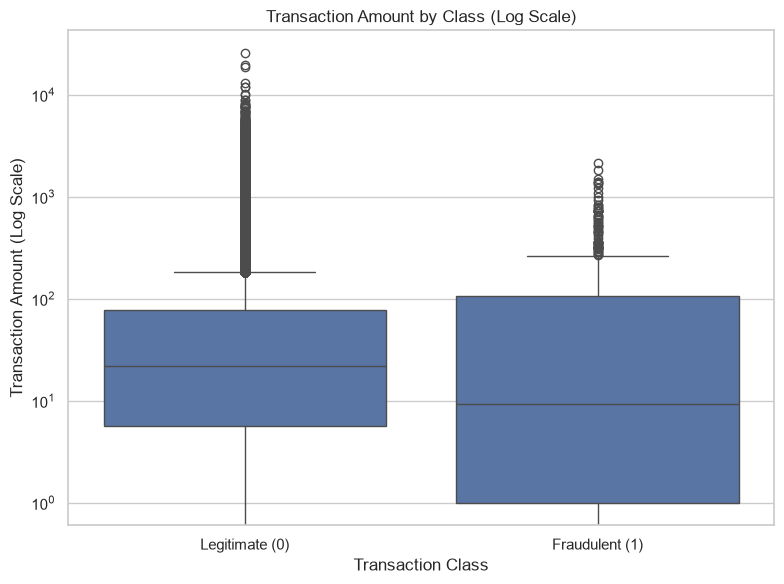

In [25]:
# Transaction Amount by Class — Log Scale

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)

plt.yscale("log")

plt.title("Transaction Amount by Class (Log Scale)")
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount (Log Scale)")
plt.xticks([0, 1], ["Legitimate (0)", "Fraudulent (1)"])

plt.tight_layout()
plt.show()

In [26]:
# Correlation Analysis

# Calculate the correlation matrix
correlation_matrix = df.corr()

# Display the correlation of each feature with the target variable
class_correlation = correlation_matrix["Class"].sort_values(ascending=False)

print("Correlation of Features with Class:")
print(class_correlation)

Correlation of Features with Class:
Class     1.000000
V11       0.154876
V4        0.133447
V2        0.091289
V21       0.040413
V19       0.034783
V20       0.020090
V8        0.019875
V27       0.017580
V28       0.009536
Amount    0.005632
V26       0.004455
V25       0.003308
V22       0.000805
V23      -0.002685
V15      -0.004223
V13      -0.004570
V24      -0.007221
Time     -0.012323
V6       -0.043643
V5       -0.094974
V9       -0.097733
V1       -0.101347
V18      -0.111485
V7       -0.187257
V3       -0.192961
V16      -0.196539
V10      -0.216883
V12      -0.260593
V14      -0.302544
V17      -0.326481
Name: Class, dtype: float64


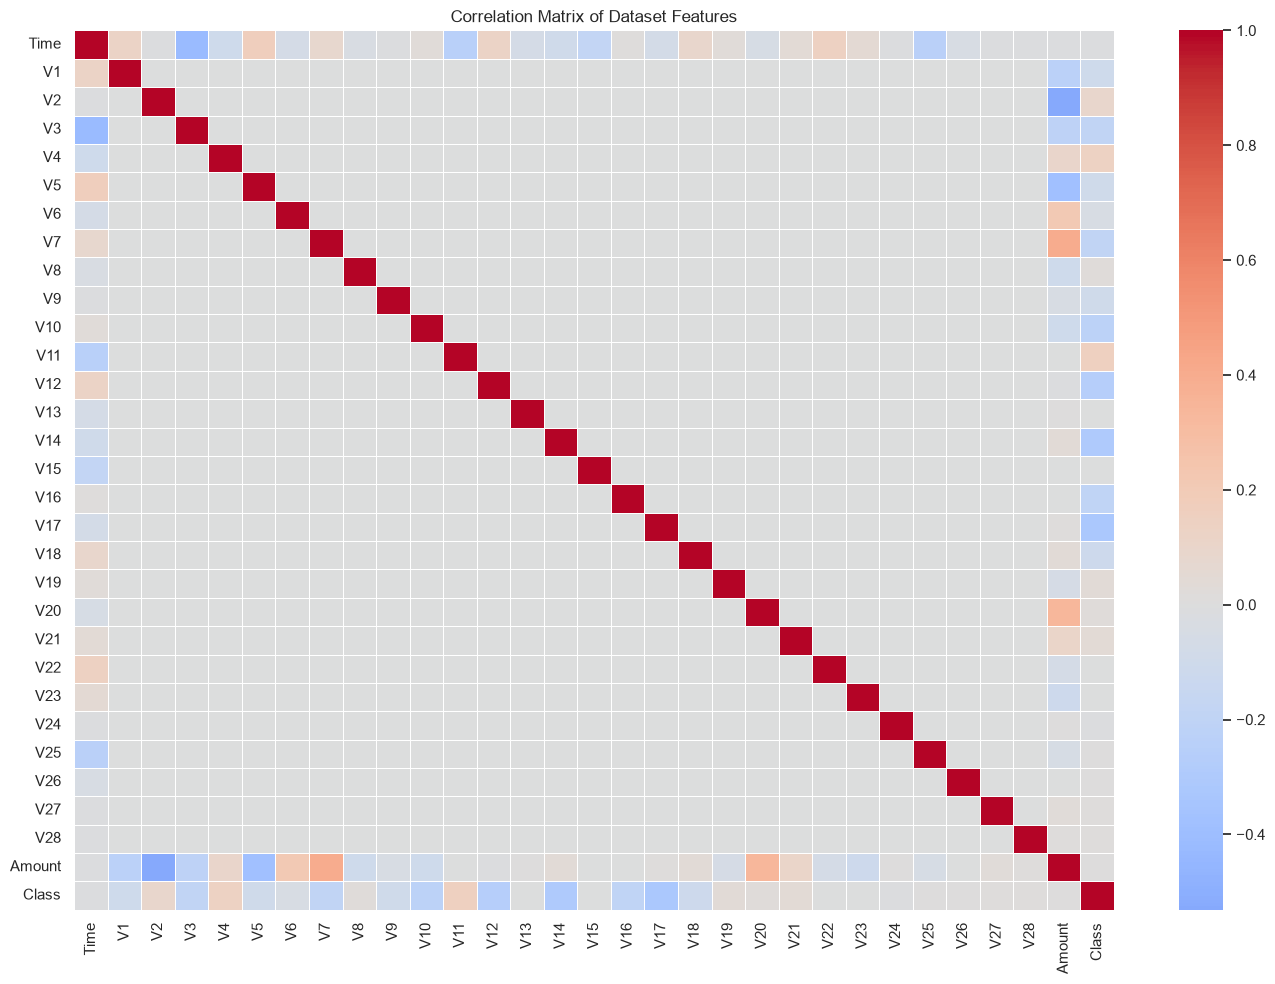

In [27]:
# Visualize the Correlation Matrix

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of Dataset Features")
plt.tight_layout()
plt.show()

In [28]:
# Identify Strongest Correlations with Class

# Find the strongest correlations with the target variable
class_correlation_strength = (
    correlation_matrix["Class"]
    .drop("Class")
    .abs()
    .sort_values(ascending=False)
)

print("Features with the Strongest Absolute Correlation with Class:")
print(class_correlation_strength.head(10))

Features with the Strongest Absolute Correlation with Class:
V17    0.326481
V14    0.302544
V12    0.260593
V10    0.216883
V16    0.196539
V3     0.192961
V7     0.187257
V11    0.154876
V4     0.133447
V18    0.111485
Name: Class, dtype: float64


### EDA Observation

From the exploratory analysis, the biggest thing I noticed is that the dataset is extremely imbalanced. Out of 284,807 transactions, 284,315 are legitimate and only 492 are fraudulent. This means that fraud accounts for just 0.1727% of all transactions.

The `Time` feature shows how the transactions are distributed over the recorded time period, while the `Amount` feature has a wide range of values, with some transactions having much larger amounts than others. The log-scale visualization made it easier to see the distribution of these values.

When comparing transaction amounts for legitimate and fraudulent transactions, the two classes show some differences in their distributions. However, there is still considerable overlap, so `Amount` by itself cannot be used to reliably identify fraud.

The correlation analysis also shows that the anonymized features (`V1` to `V28`) have different relationships with the `Class` variable. Some features show a stronger relationship with fraud, while others have a much weaker linear relationship.

Overall, the EDA makes it clear that the main challenge in this project is the very small number of fraudulent transactions compared with legitimate ones. Because of this imbalance, simply looking at accuracy would not give us a good idea of how well our model detects fraud. We will therefore need to use suitable evaluation metrics and imbalance-handling techniques when building our models.